# L17 worked example: a tiny LLM, trained on our own lecture notes

A large language model (LLM) predicts the next token of a text, again and again. Here we build
the smallest version that still works:

- **The text:** the notes of Lectures 1 to 16 of this course.
- **The tokens:** single characters.
- **The model:** the transformer of Lecture 12, with a causal mask: each position sees only
  the past.
- **The training:** next-token prediction at every position of every context window.

About 0.8 million parameters. It trains in about two minutes on a GPU.

**On Colab:** Runtime > Change runtime type > GPU, before you run anything.

## Run this first on Colab

Colab starts from its own preinstalled environment rather than this course's `uv`
environment, so run the cell below before anything else. It installs what this
notebook needs and Colab does not already have. Outside Colab it does nothing, so
you can run it or skip it.


In [ ]:
# Run this first on Colab. Anywhere else this cell does nothing.
#
# Only genuinely missing packages are installed, so Colab's own versions of
# everything it already ships are left alone.
import importlib.util
import subprocess
import sys

REQUIREMENTS = {
    "matplotlib": "matplotlib",
    "torch": "torch",
}


def _missing(module):
    try:
        return importlib.util.find_spec(module) is None
    except ModuleNotFoundError:  # the parent package is absent
        return True


if "google.colab" in sys.modules:
    need = sorted({pip for mod, pip in REQUIREMENTS.items() if _missing(mod)})
    if need:
        print("installing:", " ".join(need))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    print("Colab setup done." if need else "Colab: nothing to install.")


## 1. Libraries and device

In [1]:
import time
import urllib.request

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

if torch.cuda.is_available():
    device = "cuda"      # Colab: Runtime > Change runtime type > GPU
elif torch.backends.mps.is_available():
    device = "mps"       # a Mac with Apple silicon
else:
    device = "cpu"       # works, but about ten times slower
print("device:", device)

device: mps


## 2. The text: our lecture notes

The course site serves the source of every released lecture. We download Lectures 1 to 16, and
keep the prose, the math and the code; figures, index entries and HTML go.

In [2]:
URL = ("https://kitchingroup.cheme.cmu.edu/f26-06763/"
       "_sources/lectures/l{:02d}/notes.md")


def clean(md):
    # keep prose, math and code; drop figures, index entries, boxes, HTML
    keep, skip = [], False
    for line in md.splitlines():
        if line.startswith("```{"):          # a directive: figure, index, ...
            skip = True
            continue
        if skip:
            skip = not line.startswith("```")
            continue
        if line.startswith((":::", ":class:", "<")):
            continue
        keep.append(line)
    return "\n".join(keep)


text = ""
for n in range(1, 17):
    with urllib.request.urlopen(URL.format(n)) as r:
        text += clean(r.read().decode("utf-8")) + "\n\n"
print(f"{len(text):,} characters")
print(text[1000:1300])

668,651 characters
t yet have had to answer the question a regulator, a safety reviewer,
or a colleague joining in eighteen months will ask: can you rebuild this exact result, and
can you show where the numbers came from. Those questions are not answered by a better
architecture. They are answered by infrastructure.




## 3. Tokens: one per character

Real LLMs use subword tokens (byte-pair encoding). Characters are the simplest tokenizer that
works: every distinct character gets an integer id.

In [3]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}     # character -> token id
itos = {i: c for i, c in enumerate(chars)}     # token id -> character


def encode(s):
    return [stoi[c] for c in s]


def decode(ids):
    return "".join(itos[i] for i in ids)


print(vocab_size, "distinct characters")
print(encode("heat exchanger"))

129 distinct characters
[73, 70, 66, 85, 1, 70, 89, 68, 73, 66, 79, 72, 70, 83]


## 4. Context windows: the inputs, and the targets shifted by one

A **context window** is `block_size` characters in a row. The target at each position is the
character that comes next. One window of 128 characters is 128 next-token predictions.

In [4]:
data = torch.tensor(encode(text))
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]     # last 10% held out

block_size = 128      # context window: characters the model sees at once
batch_size = 64       # windows per training step


def get_batch(split):
    d = train_data if split == "train" else val_data
    i = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[j:j + block_size] for j in i])           # inputs
    y = torch.stack([d[j + 1:j + block_size + 1] for j in i])   # next chars
    return x.to(device), y.to(device)


x, y = get_batch("train")
print("input :", repr(decode(x[0, :40].tolist())))
print("target:", repr(decode(y[0, :40].tolist())))

input : 'ce for recent readings. Averaging over h'
target: 'e for recent readings. Averaging over he'


## 5. The model: the transformer of Lecture 12, with a causal mask

- `Block`: causal self-attention, then a small MLP, each with a residual connection.
- `is_causal=True`: position $t$ attends only to positions $1, \dots, t$.
- `TinyGPT`: token and position embeddings, four blocks, and a final layer that gives one
  logit per token in the vocabulary.

In [5]:
n_embd, n_head, n_layer = 128, 4, 4


class Block(nn.Module):
    # one transformer block: causal self-attention, then an MLP
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.qkv = nn.Linear(n_embd, 3 * n_embd)       # q, k, v at once
        self.proj = nn.Linear(n_embd, n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, h):
        B, T, C = h.shape
        q, k, v = self.qkv(self.ln1(h)).split(n_embd, dim=2)
        q, k, v = (t.view(B, T, n_head, C // n_head).transpose(1, 2)
                   for t in (q, k, v))
        a = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        h = h + self.proj(a.transpose(1, 2).reshape(B, T, C))
        return h + self.mlp(self.ln2(h))


class TinyGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, n_embd)    # token -> vector
        self.pos = nn.Embedding(block_size, n_embd)    # position -> vector
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)      # vector -> logits

    def forward(self, x):
        T = x.shape[1]
        h = self.tok(x) + self.pos(torch.arange(T, device=x.device))
        return self.head(self.ln(self.blocks(h)))      # (batch, T, vocab)

## 6. Generation: predict, sample, append, repeat

The model gives logits for the next character. Divide by the temperature, softmax, sample one,
append it, and repeat.

In [6]:
@torch.no_grad()
def generate(prompt, n=200, temperature=1.0):
    ids = torch.tensor([encode(prompt)], device=device)
    for _ in range(n):
        logits = model(ids[:, -block_size:])[:, -1, :]    # next-token logits
        p = F.softmax(logits / temperature, dim=-1)       # probabilities
        nxt = torch.multinomial(p, num_samples=1)         # sample one
        ids = torch.cat([ids, nxt], dim=1)                # append, repeat
    return decode(ids[0].tolist())


@torch.no_grad()
def val_loss(n_batches=20):
    model.eval()
    total = 0.0
    for _ in range(n_batches):
        x, y = get_batch("val")
        logits = model(x)
        total += F.cross_entropy(logits.view(-1, vocab_size),
                                 y.view(-1)).item()
    model.train()
    return total / n_batches

## 7. Training: next-token loss at every position

Each step takes 64 windows of 128 characters: 8,192 next-character predictions, averaged into
one cross-entropy loss. Every 250 steps we check the loss on held-out text and sample from the
model.

In [8]:
torch.manual_seed(0)
model = TinyGPT().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
print(sum(p.numel() for p in model.parameters()), "parameters")

steps = 2000          # on a CPU, try 500 first
losses = []           # training loss at every step
history = []          # (step, validation loss, sample) every 250 steps
start = time.time()
for step in range(steps + 1):
    x, y = get_batch("train")
    logits = model(x)                                   # (batch, T, vocab)
    loss = F.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if step % 250 == 0:
        sample = generate("The model ", n=120, temperature=0.8)
        history.append((step, val_loss(), sample))
        print(f"step {step:4d}  train {loss.item():.2f}  "
              f"val {history[-1][1]:.2f}  ({time.time() - start:.0f} s)")

842881 parameters


step    0  train 5.07  val 4.67  (2 s)


step  250  train 2.43  val 2.46  (16 s)


step  500  train 1.88  val 1.94  (31 s)


step  750  train 1.54  val 1.73  (46 s)


step 1000  train 1.44  val 1.60  (61 s)


step 1250  train 1.38  val 1.55  (73 s)


step 1500  train 1.31  val 1.51  (85 s)


step 1750  train 1.21  val 1.49  (99 s)


step 2000  train 1.22  val 1.51  (114 s)


## 8. What it learned, step by step

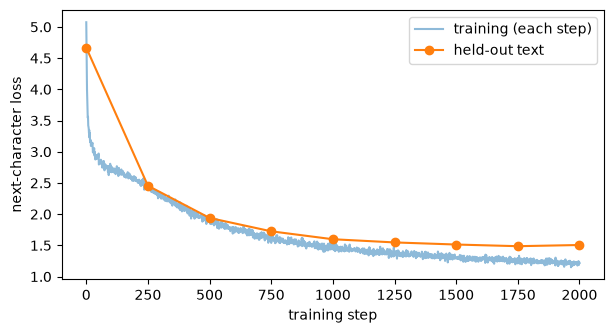

--- step 0, held-out loss 4.67
The model l₂4zé'-(u↑Ly°⁷)aQ8d¹₆−wZ²t,>zü4i{₂YGIkt└TR>P×−t_ht/dE×~r✓Y'5⁻1sK='
–+·Rσ³↑gi!(DE.├f1üh–=4⁻E-?:V[8;W^ L⁻°⁸,·ïW+Je>W✓u4^áY 

--- step 500, held-out loss 1.94
The model is onlow you be column is a sque, and with the defforemationss belast ofice the op.

## A is thilage erporally of it s a 

--- step 1000, held-out loss 1.60
The model side of the pass of there labels will as the it-learning booth a paped research for the requesed to same the supervise i 

--- step 1500, held-out loss 1.51
The model small is a well that time-series is [Sede and Lab, and a singlan compare days the columnar and at the cannot for reading 

--- step 2000, held-out loss 1.51
The model of the data, and in a \text{sk}} = \underbrace{\frac{dX}{dt} = v + G\sigma^2(x)}, \mid \hat\big z) = 1$^{(s)}
$$

The fi 



In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(losses, alpha=0.5, label="training (each step)")
ax.plot([h[0] for h in history], [h[1] for h in history], "o-",
        label="held-out text")
ax.set_xlabel("training step")
ax.set_ylabel("next-character loss")
ax.legend()
plt.show()

for step, vl, sample in history[::2]:
    print(f"--- step {step}, held-out loss {vl:.2f}")
    print(sample, "\n")

## 9. Temperature

Low temperature: the most likely characters, repetitive. High temperature: more surprising,
and more mistakes.

In [10]:
torch.manual_seed(1)
for t in (0.3, 0.8, 1.5):
    print(f"--- temperature {t}")
    print(generate("A Gaussian process ", n=200, temperature=t), "\n")

--- temperature 0.3


A Gaussian process in the data and a different statistical models.

### A file section and layers


A **fitted of stead of a column store and a strain of the same data is the same offf the same way the substrate is the  

--- temperature 0.8


A Gaussian process and the default does not exact the band file coefficients the wide, vector plant. The discipline for a strong by an Lecture 9.

The log quantition and can we course at have you beend on the score to t 

--- temperature 1.5


A Gaussian process cructor arNive," and a brieful mini-bassed flrecash uncaged defaularing most-is carryied outue: chan `y[desy''](h✓dds#p.01├x, lipproduce.
- [Slagáni lipyndbof/Jagimaus.ipynb) answerere. relans's hundr 



## 10. What it learned: our vocabulary

A fair test of what the model knows. Take one key term from each of Lectures 1 to 16, give the
model the first 60% of its characters, and let it pick the most likely next character until the
term should end. No sampling, so the answer is the same every time.

In [11]:
@torch.no_grad()
def complete(prompt, n):
    # the most likely next character, n times: no sampling
    ids = torch.tensor([encode(prompt)], device=device)
    for _ in range(n):
        nxt = model(ids[:, -block_size:])[:, -1, :].argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return decode(ids[0].tolist())[len(prompt):]


terms = ["toolchain", "environment", "database", "Parquet", "dataframe", "validation",
         "steady state", "forecast", "regression", "classification", "gradient",
         "convolution", "physics-informed", "uncertainty", "Bayesian optimization",
         "distribution"]                       # one term from each of Lectures 1 to 16
results = []
for lecture, term in enumerate(terms, 1):
    k = -(-6 * len(term) // 10)                # the first 60% of the characters
    guess = complete(" " + term[:k], len(term) - k)
    results.append((term, term[:k], guess))
    print(f"L{lecture:<3}{term[:k]:>14} + {guess!r:12} {'right' if guess == term[k:] else 'wrong'}")
right = sum(g == t[len(p):] for t, p, g in results)
print(f"{right} of {len(terms)} terms finished correctly")

L1          toolch + 'ain'        right
L2         environ + 'ment'       right
L3           datab + 'ase'        right
L4           Parqu + 'et'         right
L5          datafr + 'ame'        right


L6          valida + 'tion'       right
L7        steady s + 'tate'       right


L8           forec + 'ast'        right
L9          regres + 'sion'       right
L10      classific + 'ation'      right
L11          gradi + 'ent'        right
L12        convolu + 'tion'       right


L13     physics-in + 'to a s'     wrong
L14        uncerta + 'inty'       right


L15  Bayesian opti + 'mization'   right
L16       distribu + 'tion'       right
15 of 16 terms finished correctly


It spells our vocabulary. It does not write sentences with meaning: the samples above are fluent
nonsense. Meaning takes far more parameters and far more text, which is the scale part of the
lecture.

## Try it

- Change the prompt: `"Bayesian optimization "`, `"The data "`, `"def "`. What has it learned about
  each?
- Set the temperature to 0.01. Why does the text start to repeat?
- Double `n_embd` to 256. How many parameters now, how long does training take, and how low does
  the held-out loss go?
- Train for 6,000 steps. Watch the training and held-out losses: when do they separate, and
  what does that mean?